# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read data/mammal_sleep.csv into mammals_df; blank fields are recognized as missing.

mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [3]:
# Display the first five rows.

mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
# Display the last five rows.

mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
# Display the shape.

mammals_df.shape

(62, 11)

In [6]:
# Use .info() to inspect the data storage types and non-missing values.

mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [7]:
# Count missing values in every feature.

display(mammals_df.isnull().sum())

# Verify the original missing-value code is not present.
print("Remaining -999 missing codes:",
      (mammals_df.select_dtypes(include="number") == -999).sum().sum())


species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

Remaining -999 missing codes: 0


**What does one row represent?**

Your answer:

Each row represents one mammal species and its recorded biological characteristics, sleep durations, and danger-related ratings.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | categorical | `object` | 0 |
| `non_dreaming_sleep` | quantitative | `float64` | 14 |
| `dreaming_sleep` | quantitative | `float64` | 12 |
| `body_weight` | quantitative | `float64` | 0 |
| `brain_weight` | quantitative | `float64` | 0 |
| `max_life_span` | quantitative | `float64` | 4 |
| `gestation_time` | quantitative | `float64` | 4 |
| `predation_index` | categorical (ordinal) | `int64` | 0 |
| `sleep_exposure_index` | categorical (ordinal) | `int64` | 0 |
| `danger_index` | categorical (ordinal) | `int64` | 0 |
| `total_sleep` | quantitative | `float64` | 4 |

The ratings are stored as integers but represent ordered categories. Storage types above match the Pandas 2.3.3 rerun.

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer:

I predict that dreaming sleep and non-dreaming sleep will have a positive relationship because mammals that sleep more overall may spend more time in both sleep phases. I expect non-dreaming sleep to have the stronger relationship with total sleep because it appears to make up a larger portion of total sleep.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
# Prepare sleep_df and check sample size and sleep ranges.

sleep_df = mammals_df.dropna(
    subset=[
        "dreaming_sleep",
        "non_dreaming_sleep",
        "total_sleep",
        "danger_index",
        "predation_index"
    ]
).copy()

# Check how many records remain.
print("Original records:", len(mammals_df))
print("Complete records:", len(sleep_df))
print("Removed records:", len(mammals_df) - len(sleep_df))

# Check the minimum sleep values.
print("Minimum sleep hours:")
print(sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].min())

# Check the maximum sleep values.
print("Maximum sleep hours:")
print(sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].max())

# Confirm every retained sleep value is in the expected range.
print("All sleep measurements between 0 and 24:",
      sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]]
      .apply(lambda column: column.between(0, 24)).all().all())


Original records: 62
Complete records: 48
Removed records: 14
Minimum sleep hours:
dreaming_sleep        0.0
non_dreaming_sleep    2.1
total_sleep           2.9
dtype: float64
Maximum sleep hours:
dreaming_sleep         6.6
non_dreaming_sleep    17.9
total_sleep           19.9
dtype: float64
All sleep measurements between 0 and 24: True


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

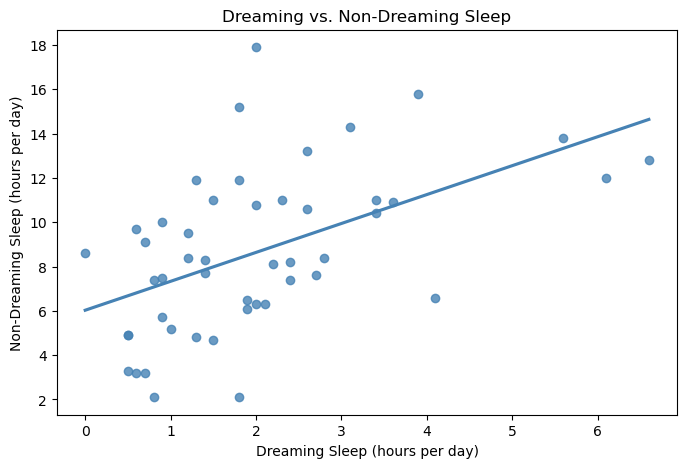

In [9]:
# Plot dreaming sleep and non-dreaming sleep.

# Set the graph size.
plt.figure(figsize=(8, 5))

# Create the regression plot.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="non_dreaming_sleep",
    color="steelblue",
    ci=None
)

# Add a title and axis labels.
plt.title("Dreaming vs. Non-Dreaming Sleep")
plt.xlabel("Dreaming Sleep (hours per day)")
plt.ylabel("Non-Dreaming Sleep (hours per day)")

# Display the graph.
plt.show()


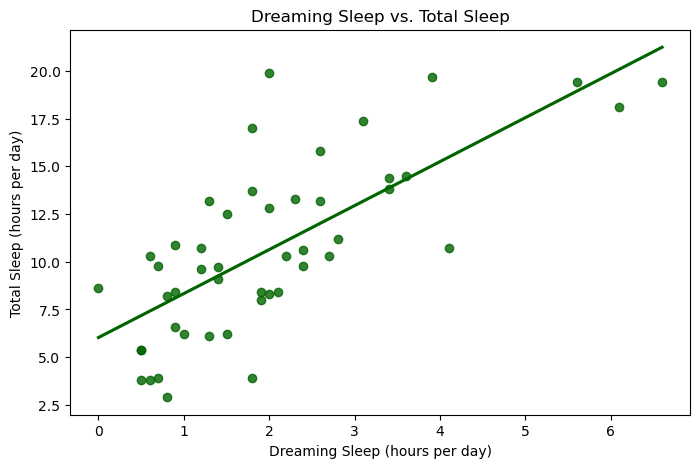

In [10]:
# Plot dreaming sleep and total sleep.


# Set the graph size.
plt.figure(figsize=(8, 5))

# Create the regression plot.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    color="darkgreen",
    ci=None
)

# Add a title and axis labels.
plt.title("Dreaming Sleep vs. Total Sleep")
plt.xlabel("Dreaming Sleep (hours per day)")
plt.ylabel("Total Sleep (hours per day)")

# Display the graph.
plt.show()


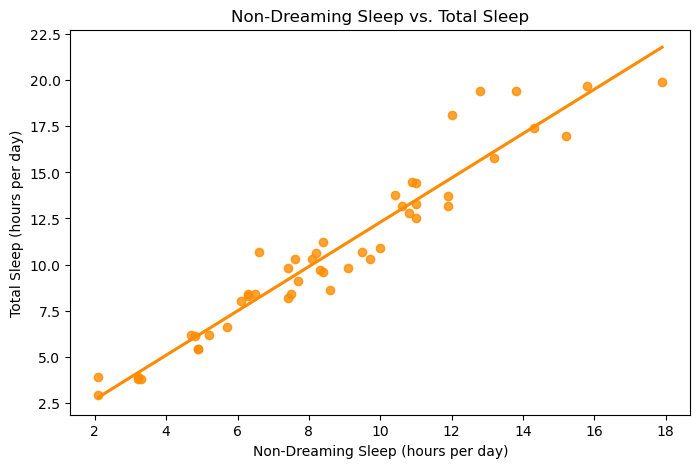

In [11]:
# Plot non-dreaming sleep and total sleep.


# Set the graph size.
plt.figure(figsize=(8, 5))

# Create the regression plot.
sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    color="darkorange",
    ci=None
)

# Add a title and axis labels.
plt.title("Non-Dreaming Sleep vs. Total Sleep")
plt.xlabel("Non-Dreaming Sleep (hours per day)")
plt.ylabel("Total Sleep (hours per day)")

# Display the graph.
plt.show()


In [12]:
# Calculate all three correlations and R-squared values.


# Calculate the three correlations.
r1 = sleep_df["dreaming_sleep"].corr(sleep_df["non_dreaming_sleep"])
r2 = sleep_df["dreaming_sleep"].corr(sleep_df["total_sleep"])
r3 = sleep_df["non_dreaming_sleep"].corr(sleep_df["total_sleep"])

# Calculate R-squared for each relationship.
r2_1 = r1 ** 2
r2_2 = r2 ** 2
r2_3 = r3 ** 2

# Display the results.
print("Dreaming vs. Non-Dreaming Sleep:")
print("Correlation:", round(r1, 3))
print("R-squared:", round(r2_1, 3))

print("\nDreaming vs. Total Sleep:")
print("Correlation:", round(r2, 3))
print("R-squared:", round(r2_2, 3))

print("\nNon-Dreaming vs. Total Sleep:")
print("Correlation:", round(r3, 3))
print("R-squared:", round(r2_3, 3))


Dreaming vs. Non-Dreaming Sleep:
Correlation: 0.514
R-squared: 0.264

Dreaming vs. Total Sleep:
Correlation: 0.727
R-squared: 0.529

Non-Dreaming vs. Total Sleep:
Correlation: 0.963
R-squared: 0.927


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:

All three graphs show positive relationships, meaning the points generally rise from left to right. The patterns are roughly linear, but their strengths differ.

Dreaming and non-dreaming sleep have a moderate positive relationship (r = 0.514, R² = 0.264), with considerable scatter. Dreaming and total sleep have a stronger positive relationship (r = 0.727, R² = 0.529), although some points are still far from the line. One unusual observation is the little brown bat, with 2.0 hours of dreaming sleep, 17.9 hours of non-dreaming sleep, and 19.9 hours of total sleep.

Non-dreaming sleep and total sleep have the strongest linear relationship (r = 0.963, R² = 0.927). The points follow the regression line closely, making this the best straight-line model. Its R² means approximately 92.7% of the variation in total sleep is accounted for by non-dreaming sleep in this linear model, while 7.3% remains unexplained.

The little brown bat is high above most points in the dreaming versus non-dreaming plot as well. In the non-dreaming versus total plot, the little brown bat and big brown bat are at the high-sleep end, but they largely follow the overall positive trend.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [13]:
# Check the sleep-phase sum and display original measurements.


# Select the original sleep measurements.
check_df = sleep_df[[
    "species",
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep"
]].copy()

# Add the two sleep phases.
check_df["phase_sum"] = (
    check_df["dreaming_sleep"] +
    check_df["non_dreaming_sleep"]
)

# Check whether the values match.
check_df["matches"] = np.isclose(
    check_df["phase_sum"],
    check_df["total_sleep"]
)

# Check all records.
print("All records match:", check_df["matches"].all())

# Display the first five records.
display(check_df.head())


All records match: True


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum,matches
1,African giant pouched rat,2.0,6.3,8.3,8.3,True
4,Asian elephant,1.8,2.1,3.9,3.9,True
5,Baboon,0.7,9.1,9.8,9.8,True
6,Big brown bat,3.9,15.8,19.7,19.7,True
7,Brazilian tapir,1.0,5.2,6.2,6.2,True


In [14]:
# Inspect the three records with the longest non-dreaming sleep.


# Find the three longest non-dreaming sleep records.
longest_sleep = sleep_df.nlargest(
    3,
    "non_dreaming_sleep"
)

# Display their original sleep measurements.
display(longest_sleep[[
    "species",
    "non_dreaming_sleep",
    "dreaming_sleep",
    "total_sleep"
]])


,species,non_dreaming_sleep,dreaming_sleep,total_sleep
32,Little brown bat,17.9,2.0,19.9
6,Big brown bat,15.8,3.9,19.7
41,Owl monkey,15.2,1.8,17.0


**Check interpretation:** All 48 retained records have matching sleep-phase sums. The three longest non-dreaming measurements are the little brown bat (17.9, 19.9), big brown bat (15.8, 19.7), and owl monkey (15.2, 17.0), where each pair is (non-dreaming sleep, total sleep) in hours per day. These values agree with the points at the upper-right end of the non-dreaming versus total sleep plot.

## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer:

Yes, mammals that spend more time in dreaming sleep generally tend to spend more time in non-dreaming sleep. The relationship is moderately positive, with a correlation of 0.514 and an R-squared value of 0.264.

Non-dreaming sleep has a stronger relationship with total sleep (r = 0.963, R² = 0.927) compared to dreaming sleep (r = 0.727, R² = 0.529). The non-dreaming sleep graph also shows points following the regression line more closely.

These results match my original prediction that non-dreaming sleep would have the stronger relationship with total sleep.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:

One limitation is that the dataset contains historical measurements and missing values. We removed 14 incomplete records, leaving 48 mammal species, which may affect how well the results represent mammals overall.

A second limitation is that total sleep is calculated by adding dreaming and non-dreaming sleep. This creates a mathematical relationship between the variables, which helps explain the strong correlation.

A stronger correlation does not automatically mean a better scientific explanation because correlation does not prove causation. Other biological and environmental factors may also influence how long mammals sleep.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer:

I did not record an initial prediction, and I do not remember what I expected before seeing the results. I cannot honestly reconstruct a before-analysis prediction now. To assess whether the indices add information, I would compare total sleep for groups at similar non-dreaming sleep durations and look for consistent vertical separation within their shared ranges. The conclusion below reports what the results actually show.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [15]:
# Count the records at each danger and predation level.

# Count the mammals in each danger category.
print("Danger Index Counts:")
print(sleep_df["danger_index"].value_counts().sort_index())

# Count the mammals in each predation category.
print("\nPredation Index Counts:")
print(sleep_df["predation_index"].value_counts().sort_index())


Danger Index Counts:
danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

Predation Index Counts:
predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64


In [16]:
# Cross-tabulate danger and predation ratings.


# Compare danger and predation categories.
category_table = pd.crosstab(
    sleep_df["danger_index"],
    sleep_df["predation_index"]
)

# Display the table.
display(category_table)


predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

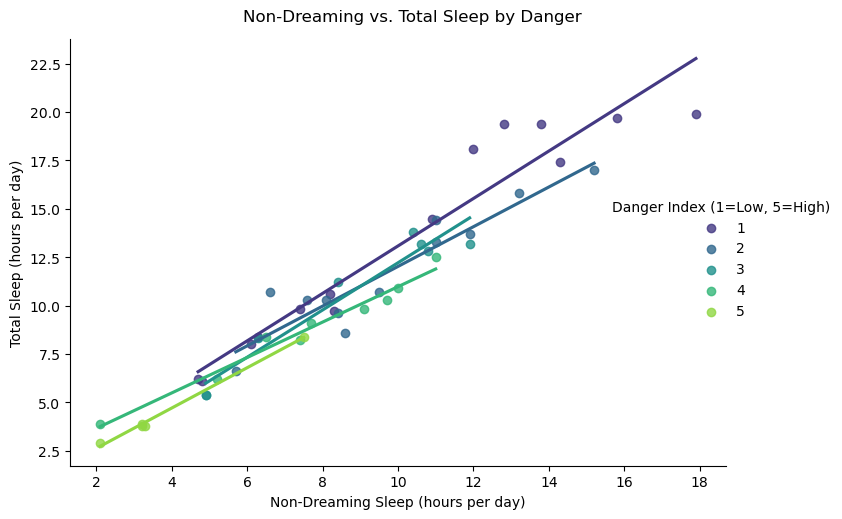

In [17]:
# Plot the non-dreaming–total sleep relationship by danger category.


# Create regression plots grouped by danger.
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=5,
    aspect=1.5
)

# Add a title and axis labels.
g.fig.suptitle("Non-Dreaming vs. Total Sleep by Danger", y=1.03)
g.set_axis_labels(
    "Non-Dreaming Sleep (hours per day)",
    "Total Sleep (hours per day)"
)

# Explain the danger levels in the legend.
g._legend.set_title("Danger Index (1=Low, 5=High)")

# Display the graph.
plt.show()


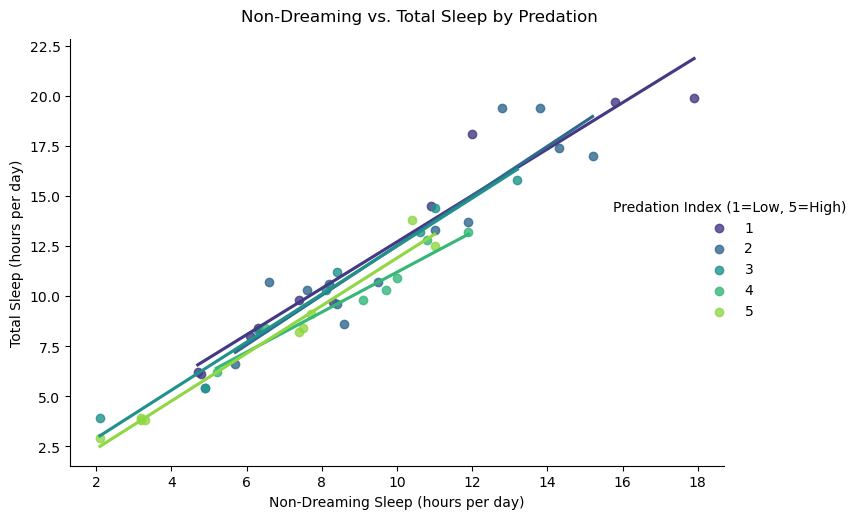

In [18]:
# Plot the non-dreaming–total sleep relationship by predation category.


# Create regression plots grouped by predation.
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=5,
    aspect=1.5
)

# Add a title and axis labels.
g.fig.suptitle("Non-Dreaming vs. Total Sleep by Predation", y=1.03)
g.set_axis_labels(
    "Non-Dreaming Sleep (hours per day)",
    "Total Sleep (hours per day)"
)

# Label the legend.
g._legend.set_title("Predation Index (1=Low, 5=High)")

# Display the graph.
plt.show()


**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:

Both plots show positive relationships, and the groups overlap considerably at similar non-dreaming sleep durations. Some lines are separated, but there is no clean separation of all five categories.

The danger groups contain 14, 12, 8, 9, and 5 species for levels 1 through 5. The predation groups contain 10, 13, 9, 7, and 9 species. The smallest groups can have lines that are strongly affected by individual points. Danger level 5 only spans 2.1 to 7.5 hours of non-dreaming sleep, while level 1 spans 4.7 to 17.9 hours, so comparisons should focus on overlapping ranges. The separate group lines can have different slopes; the additive models below instead use one shared slope with category adjustments.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [19]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [20]:
# Build and display phase_comparison for the four models.


# Create a table comparing all four models.
phase_comparison = pd.DataFrame({
    "Model": [
        "Non-dreaming only",
        "Non-dreaming + Danger",
        "Non-dreaming + Predation",
        "Non-dreaming + Both"
    ],
    "R-squared": [
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", []
        ),
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index"]
        ),
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["predation_index"]
        ),
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

# Calculate the improvement over the original model.
phase_comparison["Change from baseline"] = (
    phase_comparison["R-squared"] -
    phase_comparison["R-squared"].iloc[0]
)

# Display the results.
display(phase_comparison.round(3))


,Model,R-squared,Change from baseline
0,Non-dreaming only,0.927,0.000
1,Non-dreaming + Danger,0.943,0.016
2,Non-dreaming + Predation,0.937,0.010
3,Non-dreaming + Both,0.951,0.025


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [21]:
# Display the non-dreaming sleep range for each danger and predation rating.


# Find the sleep ranges for each danger rating.
print("Danger Index Sleep Ranges:")

danger_ranges = sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["min", "max"])

display(danger_ranges)

# Find the sleep ranges for each predation rating.
print("Predation Index Sleep Ranges:")

predation_ranges = sleep_df.groupby("predation_index")["non_dreaming_sleep"].agg(["min", "max"])

display(predation_ranges)


Danger Index Sleep Ranges:


,min,max
danger_index,,
1,4.7,17.9
2,5.7,15.2
3,4.9,11.9
4,2.1,11.0
5,2.1,7.5


Predation Index Sleep Ranges:


,min,max
predation_index,,
1,4.7,17.9
2,5.7,15.2
3,2.1,13.2
4,5.2,11.9
5,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer:

Danger groups 1 and 2 have overlapping non-dreaming sleep ranges from 5.7 to 15.2 hours per day. Group 1 ranges from 4.7 to 17.9 hours, and group 2 ranges from 5.7 to 15.2 hours. Comparing their lines within the shared range avoids extending a line beyond the observed values for either group. This overlap is a range of observed values, not a guarantee that there are observations at every duration.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer:

Adding danger and predation categories improves the model slightly. The original non-dreaming sleep model has an R-squared value of 0.927. Adding danger increases it to 0.943, an improvement of 0.016. Adding predation increases it to 0.937, an improvement of 0.010. Using both categories produces the highest R-squared value of 0.951, an improvement of approximately 0.025.

These improvements are relatively small because non-dreaming sleep already explains most of the variation in total sleep. The group plots support this because the regression lines overlap considerably, although some differences appear between categories. The higher R-squared values show better fit to the observed records but do not guarantee better predictions for new mammals.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer:

One limitation is that some danger and predation categories contain very few mammals. This makes their regression lines less reliable and more sensitive to individual observations.

Another limitation is that danger and predation ratings are closely related, so they may provide overlapping information. Although adding these categories increases R-squared, this does not prove causation or guarantee better predictions for new mammals.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer:

I predict that mammals with longer gestation times will generally sleep fewer hours per day. I expect a negative relationship between gestation time and total sleep, but I will compare my prediction with the scatterplots and correlation results to see if the data supports it.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [22]:
# Prepare gestation_df and check counts and plausible ranges.


# Create a dataset with complete gestation records.
gestation_df = mammals_df.dropna(
    subset=[
        "gestation_time",
        "total_sleep",
        "danger_index",
        "predation_index"
    ]
).copy()

# Count the records.
print("Original records:", len(mammals_df))
print("Complete records:", len(gestation_df))
print("Removed records:", len(mammals_df) - len(gestation_df))

# Check minimum and maximum values.
print("\nGestation and Sleep Ranges:")
print(gestation_df[["gestation_time", "total_sleep"]].agg(["min", "max"]))

# Check that gestation and sleep values are valid.
valid_gestation = (gestation_df["gestation_time"] > 0).all()
valid_sleep = gestation_df["total_sleep"].between(0, 24).all()

print("\nAll gestation times positive:", valid_gestation)
print("All sleep values between 0 and 24:", valid_sleep)

# Create the log transformation after checking values.
if valid_gestation and valid_sleep:
    gestation_df["log10_gestation_time"] = np.log10(
        gestation_df["gestation_time"]
    )
    print("Log transformation created successfully!")
else:
    print("Review invalid values before transforming.")


Original records: 62
Complete records: 54
Removed records: 8

Gestation and Sleep Ranges:
     gestation_time  total_sleep
min            12.0          2.6
max           645.0         19.9

All gestation times positive: True
All sleep values between 0 and 24: True
Log transformation created successfully!


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

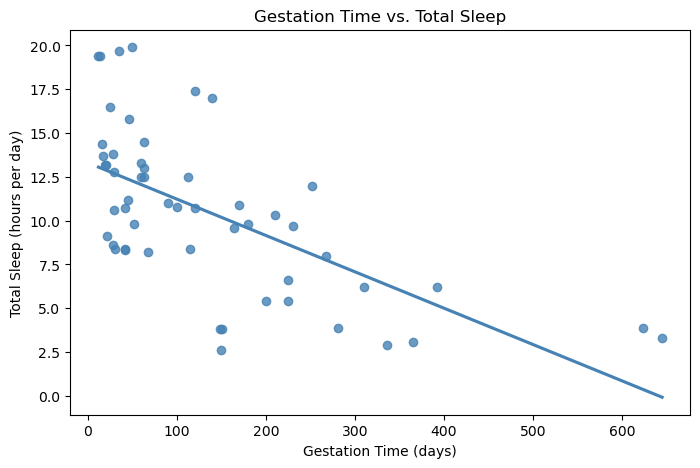

In [23]:
# Plot original gestation and sleep.


# Set the graph size.
plt.figure(figsize=(8, 5))

# Create the regression plot.
sns.regplot(
    data=gestation_df,
    x="gestation_time",
    y="total_sleep",
    color="steelblue",
    ci=None
)

# Add a title and axis labels.
plt.title("Gestation Time vs. Total Sleep")
plt.xlabel("Gestation Time (days)")
plt.ylabel("Total Sleep (hours per day)")

# Display the graph.
plt.show()


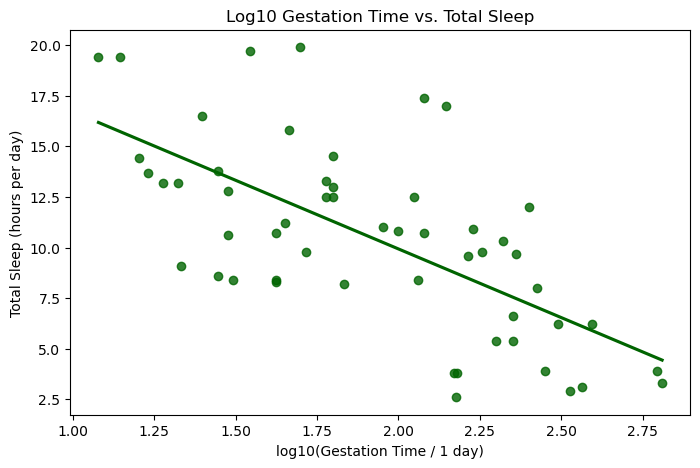

In [24]:
# Plot log gestation and sleep.


# Set the graph size.
plt.figure(figsize=(8, 5))

# Create the regression plot.
sns.regplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    color="darkgreen",
    ci=None
)

# Add a title and axis labels.
plt.title("Log10 Gestation Time vs. Total Sleep")
plt.xlabel("log10(Gestation Time / 1 day)")
plt.ylabel("Total Sleep (hours per day)")

# Display the graph.
plt.show()


In [25]:
# Calculate the two correlations and squared correlations.


# Calculate the correlation for original gestation.
original_r = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

# Calculate the correlation for log gestation.
log_r = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

# Calculate R-squared for both relationships.
original_r2 = original_r ** 2
log_r2 = log_r ** 2

# Display the original results.
print("Original Gestation vs. Total Sleep:")
print("Correlation:", round(original_r, 3))
print("R-squared:", round(original_r2, 3))

# Display the logarithmic results.
print("\nLog10 Gestation vs. Total Sleep:")
print("Correlation:", round(log_r, 3))
print("R-squared:", round(log_r2, 3))


Original Gestation vs. Total Sleep:
Correlation: -0.631
R-squared: 0.399

Log10 Gestation vs. Total Sleep:
Correlation: -0.664
R-squared: 0.44


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:

After applying the log10 transformation, the gestation values become more evenly spread across the horizontal axis, making the negative relationship slightly more linear.

The original correlation was -0.631 with an R-squared value of 0.399. After the transformation, the correlation became -0.664 and R-squared increased to 0.440.

The transformation improved the straight-line model modestly, but it did not remove the scatter. Many observations are still spread around the regression line, meaning gestation time alone does not explain all the variation in total sleep.

On the original scale, many short-gestation species cluster on the left, and the broad pattern bends as gestation increases. The log scale spreads out those shorter durations and compresses longer ones, giving a somewhat straighter downward pattern. There is still substantial vertical scatter, including species with low sleep near 150 days of gestation.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [26]:
# Count ratings in the gestation subset.


# Count mammals in each danger category.
print("Danger Index Counts:")
print(gestation_df["danger_index"].value_counts().sort_index())

# Count mammals in each predation category.
print("\nPredation Index Counts:")
print(gestation_df["predation_index"].value_counts().sort_index())


Danger Index Counts:
danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

Predation Index Counts:
predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64


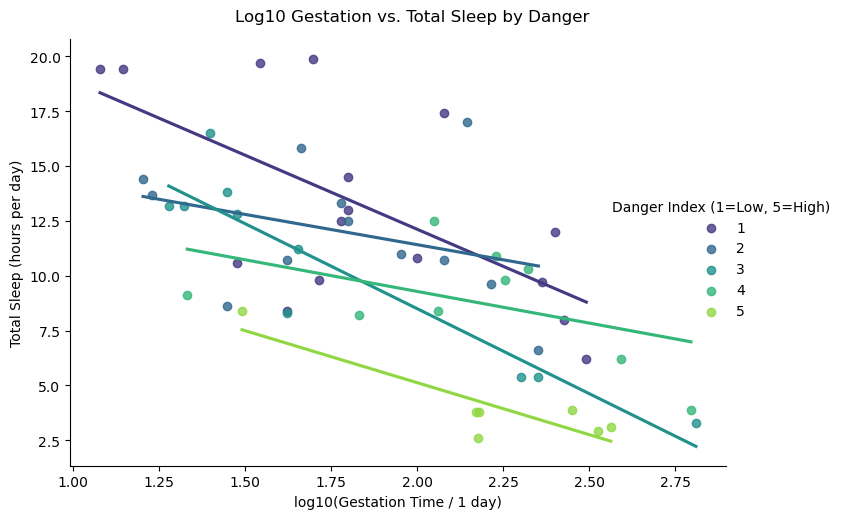

In [27]:
# Plot log gestation and sleep by danger.


# Create regression plots grouped by danger.
g = sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=5,
    aspect=1.5
)

# Add a title and axis labels.
g.fig.suptitle("Log10 Gestation vs. Total Sleep by Danger", y=1.03)

g.set_axis_labels(
    "log10(Gestation Time / 1 day)",
    "Total Sleep (hours per day)"
)

# Label the legend.
g._legend.set_title("Danger Index (1=Low, 5=High)")

# Display the graph.
plt.show()


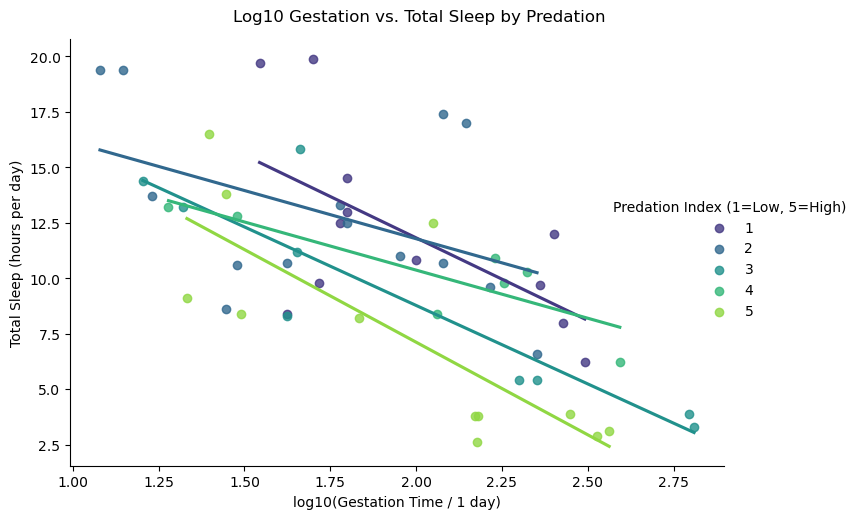

In [28]:
# Plot log gestation and sleep by predation.


# Create regression plots grouped by predation.
g = sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=5,
    aspect=1.5
)

# Add a title and axis labels.
g.fig.suptitle("Log10 Gestation vs. Total Sleep by Predation", y=1.03)

g.set_axis_labels(
    "log10(Gestation Time / 1 day)",
    "Total Sleep (hours per day)"
)

# Label the legend.
g._legend.set_title("Predation Index (1=Low, 5=High)")

# Display the graph.
plt.show()


In [29]:
# Build and display sleep_comparison for the four models.


# Create a table comparing the four models.
sleep_comparison = pd.DataFrame({
    "Model": [
        "Log Gestation Only",
        "Log Gestation + Danger",
        "Log Gestation + Predation",
        "Log Gestation + Both"
    ],
    "R-squared": [
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", []
        ),
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index"]
        ),
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["predation_index"]
        ),
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

# Calculate improvement compared to the baseline.
sleep_comparison["Change from baseline"] = (
    sleep_comparison["R-squared"] -
    sleep_comparison["R-squared"].iloc[0]
)

# Display the results.
display(sleep_comparison.round(3))


,Model,R-squared,Change from baseline
0,Log Gestation Only,0.440,0.000
1,Log Gestation + Danger,0.654,0.214
2,Log Gestation + Predation,0.592,0.151
3,Log Gestation + Both,0.694,0.254


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [30]:
# Reverse the logarithm for five records and compare with the original gestation times.


# Select the first five gestation records.
check_log = gestation_df[[
    "species",
    "gestation_time",
    "log10_gestation_time"
]].head(5).copy()

# Reverse the logarithmic transformation.
check_log["recovered_days"] = (
    10 ** check_log["log10_gestation_time"]
)

# Compare recovered days with original days.
check_log["matches"] = np.isclose(
    check_log["gestation_time"],
    check_log["recovered_days"]
)

# Display the results.
display(check_log)

# Check whether all five records match.
print("All five records match:", check_log["matches"].all())


,species,gestation_time,log10_gestation_time,recovered_days,matches
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


All five records match: True


In [31]:
# Inspect extreme gestation records.


# Find the mammal with the shortest gestation.
shortest = gestation_df.nsmallest(1, "gestation_time")

# Find the mammal with the longest gestation.
longest = gestation_df.nlargest(1, "gestation_time")

# Display the shortest gestation record.
print("Shortest Gestation:")
display(shortest[[
    "species",
    "gestation_time",
    "log10_gestation_time",
    "total_sleep"
]])

# Display the longest gestation record.
print("Longest Gestation:")
display(longest[[
    "species",
    "gestation_time",
    "log10_gestation_time",
    "total_sleep"
]])


Shortest Gestation:


,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4


Longest Gestation:


,species,gestation_time,log10_gestation_time,total_sleep
0,African elephant,645.0,2.80956,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer:

Yes, reversing the logarithm recovered the original gestation times for all five records.

The North American opossum had the shortest gestation time at 12 days and slept 19.4 hours per day. The African elephant had the longest gestation time at 645 days and slept 3.3 hours per day.

Both graphs show these same total sleep values. The logarithmic transformation changes the horizontal positions of the points but does not change their vertical positions or the original sleep measurements.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer:

The results suggest that mammals with longer gestation times generally sleep fewer hours per day, which supports my original prediction.

The original gestation model had a correlation of -0.631 and an R-squared value of 0.399. After applying the log10 transformation, the correlation became -0.664 and R-squared increased to 0.440. The transformation made the relationship slightly more linear, although considerable scatter remained.

Adding danger and predation improved the model further. Including danger increased R-squared to 0.654 (an increase of 0.214), while including predation increased it to 0.592 (an increase of 0.151). Using both categories produced the highest R-squared value of 0.694, an improvement of 0.254 over the log gestation baseline.

The group plots support these results because mammals in higher danger and predation categories often show lower total sleep at similar gestation times. However, the categories still overlap, and the improved model fit does not prove causation or guarantee better predictions for new mammals.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:

One limitation is that the dataset contains historical measurements and missing values. Eight records were removed, leaving 54 mammal species. This may affect how well the results represent mammals overall.

A second limitation is that other biological and environmental factors may influence both gestation time and total sleep. Although adding danger and predation improved R-squared, the results do not prove these factors cause differences in sleep or guarantee accurate predictions for new mammals.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes, I used AI to help explain Python functions, debug errors, and understand the statistical results. One suggestion I verified was using `np.isclose()` to check whether reversing the log10 transformation recovered the original gestation times.

I ran the code in Jupyter Notebook and confirmed that all five records matched their original measurements. I accepted the suggestion after checking the output and used the results to support my explanation.

For the final review, Codex helped complete the data-type table, move the misplaced limitations answer, add missing interpretations, and rerun the notebook. It also checked the calculations and plots against the supplied CSV. I confirmed that I did not remember or record an Investigation 2 prediction, so the notebook states that limitation instead of inventing one.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.